In [1]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from logisticRegrassionPipeline import LogisticRegScratch

Training rows: 10000
Testing rows: 2600

First 10 predicted classes:
[1 1 1 1 1 1 1 1 1 1]

First 10 predicted probabilities:
[0.78537242 0.96744658 0.5612661  0.40437135 0.98112124 0.89889941
 0.47614792 0.91688239 0.62573039 0.97578031]

Final training loss:
0.45492019795688055

Accuracy: 0.7653846153846153
Precision: 0.7820457488131204
Recall: 0.945226917057903
F1 Score: 0.85592820028342

Confusion Matrix:
[[ 178  505]
 [ 105 1812]]

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.26      0.37       683
           1       0.78      0.95      0.86      1917

    accuracy                           0.77      2600
   macro avg       0.71      0.60      0.61      2600
weighted avg       0.74      0.77      0.73      2600


Learned Feature Weights:
                  Feature    Weight  Absolute Weight
          Inventory Level -1.503872         1.503872
     stock_pressure_ratio -0.281699         0.281699
          Demand Forecas

In [2]:
data=pd.read_csv('retail_store_inventory.csv')
data

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73095,2024-01-01,S005,P0016,Furniture,East,96,8,127,18.46,73.73,20,Snowy,0,72.45,Winter
73096,2024-01-01,S005,P0017,Toys,North,313,51,101,48.43,82.57,10,Cloudy,0,83.78,Autumn
73097,2024-01-01,S005,P0018,Clothing,West,278,36,151,39.65,11.11,10,Rainy,0,10.91,Winter
73098,2024-01-01,S005,P0019,Toys,East,374,264,21,270.52,53.14,20,Rainy,0,55.80,Spring


In [3]:
data.describe()

,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Holiday/Promotion,Competitor Pricing
count,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000
mean,274.469877,136.464870,110.004473,141.494720,55.135108,10.009508,0.497305,55.146077
std,129.949514,108.919406,52.277448,109.254076,26.021945,7.083746,0.499996,26.191408
min,50.000000,0.000000,20.000000,-9.990000,10.000000,0.000000,0.000000,5.030000
25%,162.000000,49.000000,65.000000,53.670000,32.650000,5.000000,0.000000,32.680000
50%,273.000000,107.000000,110.000000,113.015000,55.050000,10.000000,0.000000,55.010000
75%,387.000000,203.000000,155.000000,208.052500,77.860000,15.000000,1.000000,77.820000
max,500.000000,499.000000,200.000000,518.550000,100.000000,20.000000,1.000000,104.940000


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                73100 non-null  str    
 1   Store ID            73100 non-null  str    
 2   Product ID          73100 non-null  str    
 3   Category            73100 non-null  str    
 4   Region              73100 non-null  str    
 5   Inventory Level     73100 non-null  int64  
 6   Units Sold          73100 non-null  int64  
 7   Units Ordered       73100 non-null  int64  
 8   Demand Forecast     73100 non-null  float64
 9   Price               73100 non-null  float64
 10  Discount            73100 non-null  int64  
 11  Weather Condition   73100 non-null  str    
 12  Holiday/Promotion   73100 non-null  int64  
 13  Competitor Pricing  73100 non-null  float64
 14  Seasonality         73100 non-null  str    
dtypes: float64(3), int64(5), str(7)
memory usage: 11.4 MB


In [5]:
new_one=data.groupby(['Store ID','Category','Region'])['Inventory Level'].value_counts()

In [6]:
new_one.head(25)

Store ID  Category  Region  Inventory Level
S001      Clothing  East    69                 7
                            286                6
                            410                6
                            478                6
                            481                5
                            324                5
                            338                5
                            318                5
                            67                 5
                            268                5
                            153                5
                            291                5
                            260                5
                            470                5
                            168                5
                            180                5
                            72                 4
                            404                4
                            126                4
                         

In [7]:
data.nunique()

Date                    731
Store ID                  5
Product ID               20
Category                  5
Region                    4
Inventory Level         451
Units Sold              498
Units Ordered           181
Demand Forecast       31608
Price                  8999
Discount                  5
Weather Condition         4
Holiday/Promotion         2
Competitor Pricing     9751
Seasonality               4
dtype: int64

In [8]:
categorical_columns=data.select_dtypes(include=['object']).columns
for col in categorical_columns:
    print(f"\nFrequency counts for {col}:")
    print(data[col].value_counts())
    print(f"Percentage distribution for {col}:")


Frequency counts for Date:
Date
2022-01-01    100
2022-01-02    100
2022-01-03    100
2022-01-04    100
2022-01-05    100
             ... 
2023-12-28    100
2023-12-29    100
2023-12-30    100
2023-12-31    100
2024-01-01    100
Name: count, Length: 731, dtype: int64
Percentage distribution for Date:

Frequency counts for Store ID:
Store ID
S001    14620
S002    14620
S003    14620
S004    14620
S005    14620
Name: count, dtype: int64
Percentage distribution for Store ID:

Frequency counts for Product ID:
Product ID
P0001    3655
P0002    3655
P0003    3655
P0004    3655
P0005    3655
P0006    3655
P0007    3655
P0008    3655
P0009    3655
P0010    3655
P0011    3655
P0012    3655
P0013    3655
P0014    3655
P0015    3655
P0016    3655
P0017    3655
P0018    3655
P0019    3655
P0020    3655
Name: count, dtype: int64
Percentage distribution for Product ID:

Frequency counts for Category:
Category
Furniture      14699
Toys           14643
Clothing       14626
Groceries      14611
Elect

C:\Users\HP\AppData\Local\Temp\ipykernel_14252\551934843.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns=data.select_dtypes(include=['object']).columns


In [9]:
data['Date'].nunique()

731

In [10]:
data.nunique()

Date                    731
Store ID                  5
Product ID               20
Category                  5
Region                    4
Inventory Level         451
Units Sold              498
Units Ordered           181
Demand Forecast       31608
Price                  8999
Discount                  5
Weather Condition         4
Holiday/Promotion         2
Competitor Pricing     9751
Seasonality               4
dtype: int64

In [11]:
data[data['Inventory Level']<=data['Units Sold']].count(
    
)

Date                  369
Store ID              369
Product ID            369
Category              369
Region                369
Inventory Level       369
Units Sold            369
Units Ordered         369
Demand Forecast       369
Price                 369
Discount              369
Weather Condition     369
Holiday/Promotion     369
Competitor Pricing    369
Seasonality           369
dtype: int64

In [12]:
data[data['Inventory Level']==0].sum()

Date                     
Store ID                 
Product ID               
Category                 
Region                   
Inventory Level         0
Units Sold              0
Units Ordered           0
Demand Forecast       0.0
Price                 0.0
Discount                0
Weather Condition        
Holiday/Promotion       0
Competitor Pricing    0.0
Seasonality              
dtype: object

In [13]:
data

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73095,2024-01-01,S005,P0016,Furniture,East,96,8,127,18.46,73.73,20,Snowy,0,72.45,Winter
73096,2024-01-01,S005,P0017,Toys,North,313,51,101,48.43,82.57,10,Cloudy,0,83.78,Autumn
73097,2024-01-01,S005,P0018,Clothing,West,278,36,151,39.65,11.11,10,Rainy,0,10.91,Winter
73098,2024-01-01,S005,P0019,Toys,East,374,264,21,270.52,53.14,20,Rainy,0,55.80,Spring


<Axes: xlabel='Units Sold', ylabel='Demand Forecast'>

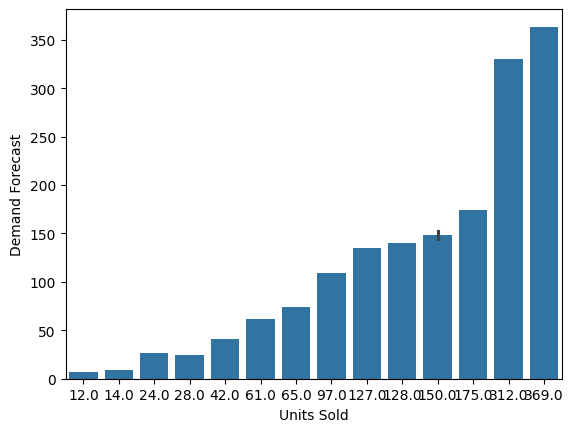

In [14]:
sb.barplot(data,x=data['Units Sold'].head(15),y=data['Demand Forecast'].head(25))

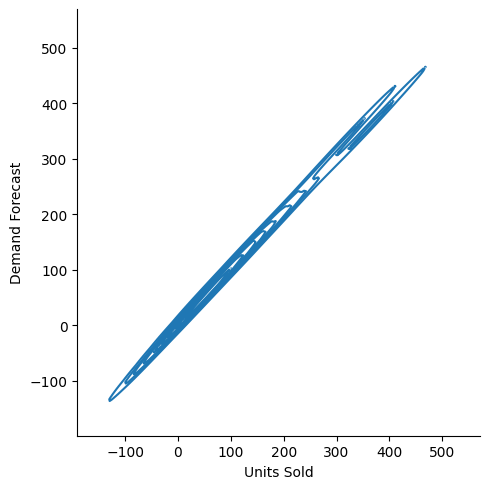

In [15]:
sb.displot(data,x=data['Units Sold'].head(15),y=data['Demand Forecast'].head(25),kind='kde')

In [16]:
data[data['Units Sold']==0]

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
63,2022-01-01,S004,P0004,Groceries,West,437,0,160,-2.40,87.23,10,Sunny,0,90.36,Spring
159,2022-01-02,S003,P0020,Electronics,East,155,0,92,9.42,57.07,10,Rainy,1,53.34,Summer
303,2022-01-04,S001,P0004,Electronics,North,209,0,123,15.37,44.81,5,Sunny,1,45.53,Winter
1107,2022-01-12,S001,P0008,Clothing,West,432,0,33,-3.55,55.07,0,Cloudy,0,51.15,Autumn
1398,2022-01-14,S005,P0019,Groceries,West,65,0,122,-0.03,82.34,20,Rainy,1,79.80,Winter
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71239,2023-12-14,S002,P0020,Clothing,West,135,0,148,0.35,90.15,15,Cloudy,0,85.24,Winter
72053,2023-12-22,S003,P0014,Toys,South,421,0,133,-4.03,11.71,15,Cloudy,0,12.11,Summer
72078,2023-12-22,S004,P0019,Electronics,East,301,0,24,-9.08,59.17,5,Cloudy,1,58.16,Autumn
72463,2023-12-26,S004,P0004,Electronics,North,101,0,70,16.66,72.31,20,Snowy,1,76.93,Summer


In [17]:
data['demand_error']=data['Units Sold']-data['Demand Forecast']
data['demand_error'].describe()

count    73100.000000
mean        -5.029850
std          8.660766
min        -20.000000
25%        -12.510000
50%         -4.990000
75%          2.470000
max         10.000000
Name: demand_error, dtype: float64

In [18]:
val=data['Inventory Level']-data['Units Sold']
val

0        104
1         54
2         37
3        408
4        152
        ... 
73095     88
73096    262
73097    242
73098    110
73099    111
Length: 73100, dtype: int64

In [19]:
data.head(20)

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality,demand_error
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn,-8.47
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn,5.96
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer,-9.02
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn,-1.18
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer,4.74
5,2022-01-01,S001,P0006,Groceries,South,138,128,102,139.82,76.83,10,Sunny,1,79.35,Winter,-11.82
6,2022-01-01,S001,P0007,Furniture,East,359,97,167,108.92,34.16,10,Rainy,1,36.55,Winter,-11.92
7,2022-01-01,S001,P0008,Clothing,North,380,312,54,329.73,97.99,5,Cloudy,0,100.09,Spring,-17.73
8,2022-01-01,S001,P0009,Electronics,West,183,175,135,174.15,20.74,10,Cloudy,0,17.66,Autumn,0.85
9,2022-01-01,S001,P0010,Toys,South,108,28,196,24.47,59.99,0,Rainy,1,61.21,Winter,3.53


In [20]:
data[['Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Holiday/Promotion', 'Competitor Pricing']].corr()

,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Holiday/Promotion,Competitor Pricing
Inventory Level,1.000000,0.589995,0.001060,0.588561,0.009140,0.004889,0.003411,0.009365
Units Sold,0.589995,1.000000,-0.000930,0.996853,0.001082,0.002576,-0.000374,0.001259
Units Ordered,0.001060,-0.000930,1.000000,-0.001102,0.004212,-0.000938,0.005446,0.004596
Demand Forecast,0.588561,0.996853,-0.001102,1.000000,0.000675,0.002338,-0.000526,0.000844
Price,0.009140,0.001082,0.004212,0.000675,1.000000,0.001509,0.002309,0.993900
Discount,0.004889,0.002576,-0.000938,0.002338,0.001509,1.000000,-0.000852,0.001958
Holiday/Promotion,0.003411,-0.000374,0.005446,-0.000526,0.002309,-0.000852,1.000000,0.001890
Competitor Pricing,0.009365,0.001259,0.004596,0.000844,0.993900,0.001958,0.001890,1.000000


<Axes: xlabel='Category', ylabel='demand_error'>

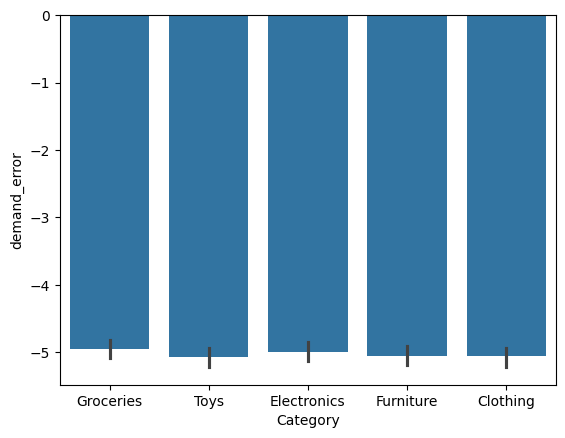

In [21]:
sb.barplot(data.head(1000),y=data['demand_error'],x=data['Category'])

In [22]:
data['StockOut']=(data['Inventory Level']<data['Demand Forecast']).astype(int)

In [23]:
data.groupby('StockOut')[["Inventory Level", "Units Sold", "Units Ordered",
     "Demand Forecast", "Price", "Discount",
     "Competitor Pricing"]
].describe().T

StockOut                             0            1
Inventory Level    count  70515.000000  2585.000000
                   mean     277.443466   193.354739
                   std      129.225290   123.255866
                   min       50.000000    50.000000
                   25%      167.000000    90.000000
                   50%      277.000000   156.000000
                   75%      389.000000   276.000000
                   max      500.000000   500.000000
Units Sold         count  70515.000000  2585.000000
                   mean     134.610565   187.047582
                   std      107.911612   123.198007
                   min        0.000000    33.000000
                   25%       47.000000    84.000000
                   50%      106.000000   149.000000
                   75%      200.000000   271.000000
                   max      496.000000   499.000000
Units Ordered      count  70515.000000  2585.000000
                   mean     109.985918   110.510638
                   std       52.262584    52.688986
                   min       20.000000    20.000000
                   25%       65.000000    64.000000
                   50%      110.000000   111.000000
                   75%      155.000000   156.000000
                   max      200.000000   200.000000
Demand Forecast    count  70515.000000  2585.000000
                   mean     139.348344   200.044704
                   std      108.107382   123.237820
                   min       -9.990000    50.860000
                   25%       51.960000    97.770000
                   50%      111.080000   162.790000
                   75%      205.680000   283.110000
                   max      497.240000   518.550000
Price              count  70515.000000  2585.000000
                   mean      55.128035    55.328062
                   std       26.027315    25.879277
                   min       10.000000    10.010000
                   25%       32.625000    33.280000
                   50%       55.050000    55.090000
                   75%       77.870000    77.440000
                   max      100.000000    99.960000
Discount           count  70515.000000  2585.000000
                   mean      10.002411    10.203095
                   std        7.086944     6.994535
                   min        0.000000     0.000000
                   25%        5.000000     5.000000
                   50%       10.000000    10.000000
                   75%       15.000000    15.000000
                   max       20.000000    20.000000
Competitor Pricing count  70515.000000  2585.000000
                   mean      55.136371    55.410855
                   std       26.196920    26.044249
                   min        5.030000     5.460000
                   25%       32.650000    33.170000
                   50%       55.010000    55.070000
                   75%       77.830000    77.420000
                   max      104.940000   104.420000

In [24]:
data[data['Units Sold']==0].head(10)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality,demand_error,StockOut
63,2022-01-01,S004,P0004,Groceries,West,437,0,160,-2.40,87.23,10,Sunny,0,90.36,Spring,2.40,0
159,2022-01-02,S003,P0020,Electronics,East,155,0,92,9.42,57.07,10,Rainy,1,53.34,Summer,-9.42,0
303,2022-01-04,S001,P0004,Electronics,North,209,0,123,15.37,44.81,5,Sunny,1,45.53,Winter,-15.37,0
1107,2022-01-12,S001,P0008,Clothing,West,432,0,33,-3.55,55.07,0,Cloudy,0,51.15,Autumn,3.55,0
1398,2022-01-14,S005,P0019,Groceries,West,65,0,122,-0.03,82.34,20,Rainy,1,79.80,Winter,0.03,0
1815,2022-01-19,S001,P0016,Clothing,East,50,0,166,13.36,98.44,5,Snowy,0,101.34,Autumn,-13.36,0
1934,2022-01-20,S002,P0015,Clothing,North,241,0,184,12.86,48.74,15,Sunny,1,47.70,Winter,-12.86,0
2036,2022-01-21,S002,P0017,Clothing,West,254,0,112,18.61,84.07,20,Cloudy,0,79.15,Winter,-18.61,0
2314,2022-01-24,S001,P0015,Toys,East,107,0,167,13.73,85.75,20,Sunny,1,86.61,Spring,-13.73,0
2818,2022-01-29,S001,P0019,Electronics,West,141,0,150,18.19,93.32,10,Sunny,1,96.19,Winter,-18.19,0


In [25]:
data.groupby(["Region",'Category'])['Units Sold'].count()

Region  Category   
East    Clothing       3753
        Electronics    3705
        Furniture      3607
        Groceries      3684
        Toys           3600
North   Clothing       3528
        Electronics    3589
        Furniture      3720
        Groceries      3652
        Toys           3739
South   Clothing       3651
        Electronics    3606
        Furniture      3684
        Groceries      3704
        Toys           3652
West    Clothing       3694
        Electronics    3621
        Furniture      3688
        Groceries      3571
        Toys           3652
Name: Units Sold, dtype: int64

In [26]:
data.groupby(['Category'])['Units Sold'].count()

Category
Clothing       14626
Electronics    14521
Furniture      14699
Groceries      14611
Toys           14643
Name: Units Sold, dtype: int64

In [27]:
data.groupby(['Region'])['Units Sold'].count()

Region
East     18349
North    18228
South    18297
West     18226
Name: Units Sold, dtype: int64

In [28]:
data.groupby(['Product ID'])['Units Sold'].mean().sort_values()

Product ID
P0002    133.468399
P0008    133.669767
P0012    134.519836
P0018    134.760876
P0003    134.960055
P0004    135.567989
P0010    135.832832
P0006    136.013953
P0019    136.224077
P0001    136.268399
P0007    136.613133
P0011    136.624350
P0017    136.938440
P0013    136.968263
P0009    137.369631
P0005    137.796990
P0015    138.791518
P0014    138.884268
P0020    138.907798
P0016    139.116826
Name: Units Sold, dtype: float64

In [29]:
data.groupby(["Store ID","Region"])['Units Sold'].mean().sort_values()

Store ID  Region
S005      West      133.567827
S001      East      134.740680
S004      South     134.872411
          North     135.124795
S001      South     135.170898
          West      135.206310
S002      South     135.271588
S001      North     135.446797
S004      West      135.616895
S002      West      135.653158
          North     135.672281
S004      East      135.899724
S003      East      136.547030
S002      East      137.199520
S003      North     137.605070
S005      North     137.779274
S003      West      137.993126
S005      South     138.716157
          East      139.899155
S003      South     141.233551
Name: Units Sold, dtype: float64

In [30]:
data.groupby(
    ["Store ID", "Region", "Product ID"]
)['Units Sold'].mean().describe()

count    400.000000
mean     136.462463
std        8.500909
min      112.150538
25%      130.943765
50%      136.425529
75%      142.235242
max      159.803191
Name: Units Sold, dtype: float64

In [31]:
data.groupby(
    ["Store ID", "Region", "Product ID"]
)["Inventory Level"].mean().describe()

count    400.000000
mean     274.457346
std       10.592513
min      240.247126
25%      267.122599
50%      273.995162
75%      281.433187
max      310.075581
Name: Inventory Level, dtype: float64

In [32]:
data.groupby("Store ID")["Units Sold"].mean()

Store ID
S001    135.140219
S002    135.958618
S003    138.351300
S004    135.379275
S005    137.494938
Name: Units Sold, dtype: float64

In [33]:
data.groupby("Region")["Units Sold"].mean()

Region
East     136.861137
North    136.326860
South    137.060666
West     135.605838
Name: Units Sold, dtype: float64

In [34]:
data.groupby("Category")["Units Sold"].mean()

Category
Clothing       136.685765
Electronics    135.006680
Furniture      137.765630
Groceries      136.916159
Toys           135.934235
Name: Units Sold, dtype: float64

In [35]:
data.groupby(
    ["Store ID", "Region", "Category"]
)["Units Sold"].mean().describe()

count    100.000000
mean     136.441421
std        4.055152
min      127.857534
25%      133.423881
50%      136.151551
75%      139.739468
max      146.388889
Name: Units Sold, dtype: float64

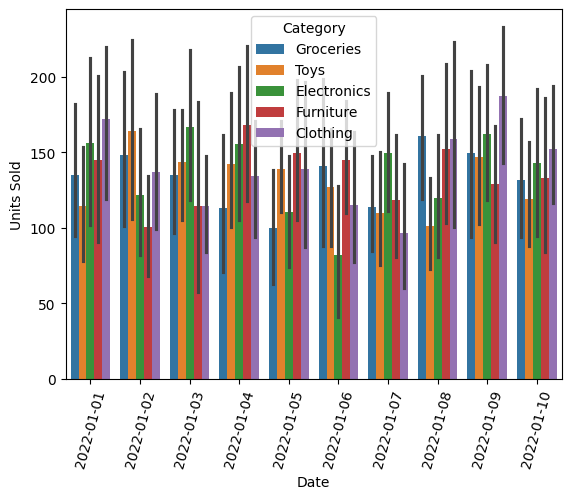

In [36]:
sb.barplot(data.head(1000),y='Units Sold',x='Date',hue='Category')
map.xticks(rotation=75)
map.show()

In [37]:
data.groupby(
    ['Date','Store ID', 'Region', 'Category', 'Product ID']
)['Units Ordered'].value_counts().head(25)

Date        Store ID  Region  Category     Product ID  Units Ordered
2022-01-01  S001      East    Clothing     P0019       186              1
                              Electronics  P0005       135              1
                              Furniture    P0007       167              1
                              Toys         P0020       166              1
                      North   Clothing     P0008       54               1
                                           P0015       154              1
                              Electronics  P0016       69               1
                              Groceries    P0001       55               1
                              Toys         P0004       164              1
                      South   Clothing     P0018       47               1
                              Furniture    P0011       153              1
                              Groceries    P0006       102              1
                              Toys         

In [38]:
data

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality,demand_error,StockOut
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn,-8.47,0
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn,5.96,0
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer,-9.02,0
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn,-1.18,0
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer,4.74,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73095,2024-01-01,S005,P0016,Furniture,East,96,8,127,18.46,73.73,20,Snowy,0,72.45,Winter,-10.46,0
73096,2024-01-01,S005,P0017,Toys,North,313,51,101,48.43,82.57,10,Cloudy,0,83.78,Autumn,2.57,0
73097,2024-01-01,S005,P0018,Clothing,West,278,36,151,39.65,11.11,10,Rainy,0,10.91,Winter,-3.65,0
73098,2024-01-01,S005,P0019,Toys,East,374,264,21,270.52,53.14,20,Rainy,0,55.80,Spring,-6.52,0


In [39]:
data.groupby(
    ['Store ID','Region','Category','Product ID','Date']
).size().value_counts()

1    73100
Name: count, dtype: int64

In [40]:
data.groupby(
    ['Store ID', 'Product ID']
)['Date'].nunique().describe()

count    100.0
mean     731.0
std        0.0
min      731.0
25%      731.0
50%      731.0
75%      731.0
max      731.0
Name: Date, dtype: float64

In [41]:
data = data.sort_values(
    ["Store ID", "Product ID", 'Category','Region',"Date"]
)

data['future_7d_demand']=data.groupby(["Store ID", "Product ID", 'Category','Region'])["Demand Forecast"].transform(lambda x: x.shift(-1).rolling(7).sum().shift(-6))  



In [42]:
data[[
    "Store ID",
    "Product ID",
    "Date",
    "Inventory Level",
    "Demand Forecast",
    "future_7d_demand"
]].head(15)

,Store ID,Product ID,Date,Inventory Level,Demand Forecast,future_7d_demand
5100,S001,P0001,2022-02-21,337,346.41,1090.19
6800,S001,P0001,2022-03-10,285,161.02,1169.13
14000,S001,P0001,2022-05-21,494,323.92,899.62
14200,S001,P0001,2022-05-23,114,67.77,987.50
14500,S001,P0001,2022-05-26,211,207.14,969.80
15000,S001,P0001,2022-05-31,111,117.21,941.67
16400,S001,P0001,2022-06-14,133,121.46,1172.82
20200,S001,P0001,2022-07-22,422,91.67,1225.20
21400,S001,P0001,2022-08-03,329,239.96,1246.38
21900,S001,P0001,2022-08-08,338,54.41,1463.93


In [43]:
data = data.sort_values(
    ["Store ID", "Product ID", 'Category','Region',"Date"]
)

data['val']=data.groupby(["Store ID", "Product ID", 'Category','Region'])["Demand Forecast"].transform(lambda x: x.shift(-1).rolling(7).sum())  



In [44]:
data.drop(columns=['val'],inplace=True)

In [45]:
data

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality,demand_error,StockOut,future_7d_demand
5100,2022-02-21,S001,P0001,Clothing,East,337,337,136,346.41,96.55,10,Sunny,0,100.10,Winter,-9.41,1,1090.19
6800,2022-03-10,S001,P0001,Clothing,East,285,147,184,161.02,24.69,10,Snowy,1,20.00,Spring,-14.02,0,1169.13
14000,2022-05-21,S001,P0001,Clothing,East,494,314,20,323.92,75.60,0,Sunny,1,76.80,Winter,-9.92,0,899.62
14200,2022-05-23,S001,P0001,Clothing,East,114,66,46,67.77,19.09,5,Snowy,0,23.61,Spring,-1.77,0,987.50
14500,2022-05-26,S001,P0001,Clothing,East,211,200,114,207.14,14.76,5,Sunny,1,14.03,Autumn,-7.14,0,969.80
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66799,2023-10-30,S005,P0020,Toys,West,463,371,195,376.79,29.52,15,Sunny,1,24.95,Summer,-5.79,0,NaN
67899,2023-11-10,S005,P0020,Toys,West,425,180,179,177.61,52.11,15,Cloudy,1,51.03,Autumn,2.39,0,NaN
69399,2023-11-25,S005,P0020,Toys,West,430,289,29,306.38,89.93,15,Sunny,0,91.14,Summer,-17.38,0,NaN
71199,2023-12-13,S005,P0020,Toys,West,51,12,112,29.90,21.84,15,Sunny,1,26.79,Spring,-17.90,0,NaN


In [46]:
data = data.sort_values(
    ["Store ID", "Product ID", "Date"]
).reset_index(drop=True)

In [47]:
data["rolling_7d_sales"] = (
    data.groupby(["Store ID", "Product ID"])["Units Sold"]
        .transform(lambda x: x.shift(1).rolling(7).sum())
)

In [48]:
data["rolling_14d_sales"] = (
    data.groupby(["Store ID", "Product ID"])["Units Sold"]
        .transform(lambda x: x.shift(1).rolling(14).sum())
)

In [49]:
lead_time = 3

data["lead_time_demand"] = (
    data.groupby(["Store ID", "Product ID"])["Demand Forecast"]
        .transform(
            lambda x: x.shift(-1)
                       .rolling(lead_time)
                       .sum()
                       .shift(-(lead_time - 1))
        )
)

In [50]:
data["inventory_to_demand_ratio"] = (
    data["Inventory Level"] /
    (data["rolling_7d_sales"] / 7)
)

In [51]:
data["inventory_to_demand_ratio"] = (
    data["Inventory Level"] /
    (data["rolling_7d_sales"] / 7).replace(0, np.nan)
)

In [52]:
data["previous_7d_sales"] = (
    data.groupby(["Store ID", "Product ID"])["Units Sold"]
        .transform(
            lambda x: x.shift(1).rolling(14).sum()
        )
)

In [53]:
data["recent_7d_sales"] = (
    data.groupby(["Store ID", "Product ID"])["Units Sold"]
        .transform(lambda x: x.shift(1).rolling(7).sum())
)

data["previous_7d_sales"] = (
    data.groupby(["Store ID", "Product ID"])["Units Sold"]
        .transform(lambda x: x.shift(8).rolling(7).sum())
)

data["sales_trend"] = (
    data["recent_7d_sales"] -
    data["previous_7d_sales"]
)

In [54]:
data.groupby(['Store ID','Region','Category','Date'])[['Inventory Level','Units Sold']].value_counts().head(25)

Store ID  Region  Category  Date        Inventory Level  Units Sold
S001      East    Clothing  2022-01-01  352              257           1
                            2022-01-02  92               74            1
                            2022-01-03  282              199           1
                                        72               2             1
                                        148              31            1
                            2022-01-04  77               7             1
                            2022-01-06  204              97            1
                                        481              429           1
                            2022-01-07  193              64            1
                                        178              161           1
                            2022-01-09  247              194           1
                            2022-01-10  324              113           1
                                        413             

In [55]:
data["stockout_risk"] = (
    data["Inventory Level"] < data["lead_time_demand"]
).astype(int)

In [56]:
data

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,...,StockOut,future_7d_demand,rolling_7d_sales,rolling_14d_sales,lead_time_demand,inventory_to_demand_ratio,previous_7d_sales,recent_7d_sales,sales_trend,stockout_risk
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,...,0,1093.65,NaN,NaN,151.17,NaN,NaN,NaN,NaN,0
1,2022-01-02,S001,P0001,Groceries,West,116,81,104,92.94,27.95,...,0,1256.02,NaN,NaN,208.50,NaN,NaN,NaN,NaN,1
2,2022-01-03,S001,P0001,Electronics,West,154,5,189,5.36,62.70,...,0,827.57,NaN,NaN,242.23,NaN,NaN,NaN,NaN,1
3,2022-01-04,S001,P0001,Groceries,South,85,58,193,52.87,77.88,...,0,1009.63,NaN,NaN,307.28,NaN,NaN,NaN,NaN,1
4,2022-01-05,S001,P0001,Groceries,South,238,147,37,150.27,28.46,...,0,1013.98,NaN,NaN,157.85,NaN,NaN,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73095,2023-12-28,S005,P0020,Groceries,South,198,56,27,50.18,21.75,...,0,NaN,936.0,1921.0,490.15,1.480769,985.0,936.0,-49.0,1
73096,2023-12-29,S005,P0020,Clothing,East,446,268,30,267.54,85.58,...,0,NaN,832.0,1897.0,224.94,3.752404,1065.0,832.0,-233.0,0
73097,2023-12-30,S005,P0020,Toys,North,251,149,181,162.92,79.48,...,0,NaN,872.0,1885.0,NaN,2.014908,1013.0,872.0,-141.0,0
73098,2023-12-31,S005,P0020,Furniture,East,64,40,99,59.69,90.79,...,0,NaN,801.0,2031.0,NaN,0.559301,1230.0,801.0,-429.0,0


In [57]:
data = data.dropna(subset=["lead_time_demand"])

In [58]:
data["stockout_risk"] = (
    data["Inventory Level"] < data["lead_time_demand"]
).astype(int)

In [59]:
data

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,...,StockOut,future_7d_demand,rolling_7d_sales,rolling_14d_sales,lead_time_demand,inventory_to_demand_ratio,previous_7d_sales,recent_7d_sales,sales_trend,stockout_risk
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,...,0,1093.65,NaN,NaN,151.17,NaN,NaN,NaN,NaN,0
1,2022-01-02,S001,P0001,Groceries,West,116,81,104,92.94,27.95,...,0,1256.02,NaN,NaN,208.50,NaN,NaN,NaN,NaN,1
2,2022-01-03,S001,P0001,Electronics,West,154,5,189,5.36,62.70,...,0,827.57,NaN,NaN,242.23,NaN,NaN,NaN,NaN,1
3,2022-01-04,S001,P0001,Groceries,South,85,58,193,52.87,77.88,...,0,1009.63,NaN,NaN,307.28,NaN,NaN,NaN,NaN,1
4,2022-01-05,S001,P0001,Groceries,South,238,147,37,150.27,28.46,...,0,1013.98,NaN,NaN,157.85,NaN,NaN,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73092,2023-12-25,S005,P0020,Furniture,South,322,31,187,46.54,26.51,...,0,NaN,1071.0,2062.0,344.12,2.104575,991.0,1071.0,80.0,1
73093,2023-12-26,S005,P0020,Clothing,North,288,153,81,164.99,88.45,...,0,NaN,989.0,2089.0,446.67,2.038423,1100.0,989.0,-111.0,1
73094,2023-12-27,S005,P0020,Toys,West,144,138,109,128.95,17.53,...,0,NaN,889.0,1795.0,480.64,1.133858,906.0,889.0,-17.0,1
73095,2023-12-28,S005,P0020,Groceries,South,198,56,27,50.18,21.75,...,0,NaN,936.0,1921.0,490.15,1.480769,985.0,936.0,-49.0,1


In [60]:
print(data["stockout_risk"].value_counts())
print(data["stockout_risk"].value_counts(normalize=True))

stockout_risk
1    53056
0    19744
Name: count, dtype: int64
stockout_risk
1    0.728791
0    0.271209
Name: proportion, dtype: float64


In [61]:
denominator = data["Inventory Level"] + data["Units Ordered"]

data["stock_pressure_ratio"] = (
    data["Units Sold"] / denominator.replace(0, np.nan)
)

In [62]:
data.drop(columns='StockOut')

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,...,future_7d_demand,rolling_7d_sales,rolling_14d_sales,lead_time_demand,inventory_to_demand_ratio,previous_7d_sales,recent_7d_sales,sales_trend,stockout_risk,stock_pressure_ratio
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,...,1093.65,NaN,NaN,151.17,NaN,NaN,NaN,NaN,0,0.444056
1,2022-01-02,S001,P0001,Groceries,West,116,81,104,92.94,27.95,...,1256.02,NaN,NaN,208.50,NaN,NaN,NaN,NaN,1,0.368182
2,2022-01-03,S001,P0001,Electronics,West,154,5,189,5.36,62.70,...,827.57,NaN,NaN,242.23,NaN,NaN,NaN,NaN,1,0.014577
3,2022-01-04,S001,P0001,Groceries,South,85,58,193,52.87,77.88,...,1009.63,NaN,NaN,307.28,NaN,NaN,NaN,NaN,1,0.208633
4,2022-01-05,S001,P0001,Groceries,South,238,147,37,150.27,28.46,...,1013.98,NaN,NaN,157.85,NaN,NaN,NaN,NaN,0,0.534545
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73092,2023-12-25,S005,P0020,Furniture,South,322,31,187,46.54,26.51,...,NaN,1071.0,2062.0,344.12,2.104575,991.0,1071.0,80.0,1,0.060904
73093,2023-12-26,S005,P0020,Clothing,North,288,153,81,164.99,88.45,...,NaN,989.0,2089.0,446.67,2.038423,1100.0,989.0,-111.0,1,0.414634
73094,2023-12-27,S005,P0020,Toys,West,144,138,109,128.95,17.53,...,NaN,889.0,1795.0,480.64,1.133858,906.0,889.0,-17.0,1,0.545455
73095,2023-12-28,S005,P0020,Groceries,South,198,56,27,50.18,21.75,...,NaN,936.0,1921.0,490.15,1.480769,985.0,936.0,-49.0,1,0.248889


In [ ]:
# 1. Load dataset
data = pd.read_csv("Dataset/retail_store_inventory.csv")
ata = pd.read_csv(
    r"C:\Users\HP\OneDrive\Desktop\New folder\Dataset\retail_store_inventory.csv"
)

data["Date"] = pd.to_datetime(data["Date"])
data = data.sort_values(["Store ID", "Product ID", "Date"]).copy()


# ==========================================
# 2. FEATURE ENGINEERING
# ==========================================

group_cols = ["Store ID", "Product ID"]

# Previous 7 days of sales
data["rolling_7d_sales"] = (
    data.groupby(group_cols)["Units Sold"]
    .transform(lambda s: s.shift(1).rolling(7).sum())
)

# Previous 14 days of sales
data["rolling_14d_sales"] = (
    data.groupby(group_cols)["Units Sold"]
    .transform(lambda s: s.shift(1).rolling(14).sum())
)

# Previous 7-day sales compared with the 7 days before that
data["previous_7d_sales"] = (
    data.groupby(group_cols)["Units Sold"]
    .transform(lambda s: s.shift(8).rolling(7).sum())
)

data["sales_trend"] = (
    data["rolling_7d_sales"] - data["previous_7d_sales"]
)

# Inventory coverage based on recent average daily sales
avg_daily_sales = data["rolling_7d_sales"] / 7

data["inventory_to_demand_ratio"] = (
    data["Inventory Level"] /
    avg_daily_sales.replace(0, np.nan)
)

# Current sales relative to current stock plus orders
denominator = data["Inventory Level"] + data["Units Ordered"]

data["stock_pressure_ratio"] = (
    data["Units Sold"] /
    denominator.replace(0, np.nan)
)


# ==========================================
# 3. CREATE TARGET
# ==========================================

# Assumption: supplier replenishment lead time = 3 days
lead_time = 3

data["lead_time_demand"] = (
    data.groupby(group_cols)["Demand Forecast"]
    .transform(
        lambda s: s.shift(-1)
                   .rolling(lead_time)
                   .sum()
                   .shift(-(lead_time - 1))
    )
)

# 1 = inventory insufficient for forecast demand
# 0 = inventory sufficient for forecast demand
data["stockout_risk"] = (
    data["Inventory Level"] < data["lead_time_demand"]
).astype(int)

# Remove rows without enough future data to construct the target
data = data.dropna(subset=["lead_time_demand"]).copy()


features = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Demand Forecast",
    "rolling_7d_sales",
    "rolling_14d_sales",
    "inventory_to_demand_ratio",
    "sales_trend",
    "stock_pressure_ratio",
    "Price",
    "Discount",
    "Competitor Pricing"
]

target = "stockout_risk"

X = data[features].apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(data[target], errors="coerce")

X = X.replace([np.inf, -np.inf], np.nan)

valid_rows = X.notna().all(axis=1) & y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

if not set(y.unique()).issubset({0, 1}):
    raise ValueError("Target must contain only binary labels 0 and 1.")

if y.nunique() != 2:
    raise ValueError("Dataset must contain both target classes.")


# 2. Split data
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fit scaler on training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

y_train_np = y_train.to_numpy()
y_val_np = y_val.to_numpy()


# 3. Hyperparameter values to test
learning_rates = [0.001, 0.01, 0.05, 0.1,0.18,0.24,0.35]
epoch_values = [500, 1000, 2500,4000,4500,5000,3500]
threshold_values = [0.31, 0.35, 0.40, 0.45, 0.50, 0.60,0.71,0.75,0.21,0.18]

results = []
loss_curves = {}

# 4. Train and evaluate each configuration
for lr in learning_rates:
    for epochs in epoch_values:

        print(f"Training: lr={lr}, epochs={epochs}")

        model = LogisticRegScratch(
            learn_rate=lr,
            epochs=epochs
        )

        model.fit(X_train_scaled, y_train_np)

        # Save gradient descent history
        loss_curves[(lr, epochs)] = model.loss_history.copy()

        # Calculate probabilities only once per trained model
        probabilities = np.asarray(
            model.predict_proba(X_val_scaled)
        ).ravel()

        # Test multiple decision thresholds
        for threshold in threshold_values:

            predictions = (
                probabilities >= threshold
            ).astype(int)

            tn, fp, fn, tp = confusion_matrix(
                y_val_np,
                predictions,
                labels=[0, 1]
            ).ravel()

            results.append({
                "Learning Rate": lr,
                "Epochs": epochs,
                "Threshold": threshold,
                "Accuracy": accuracy_score(
                    y_val_np, predictions
                ),
                "Precision": precision_score(
                    y_val_np, predictions,
                    zero_division=0
                ),
                "Recall": recall_score(
                    y_val_np, predictions,
                    zero_division=0
                ),
                "F1 Score": f1_score(
                    y_val_np, predictions,
                    zero_division=0
                ),
                "TN": tn,
                "FP": fp,
                "FN": fn,
                "TP": tp,
                "Final Loss": model.loss_history[-1]
            })


# 5. Display the best configurations
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

print("\nTOP 15 CONFIGURATIONS")
print(results_df.head(15).round(4).to_string(index=False))

results_df.to_csv(
    "Dataset/hyperparameter_results.csv",
    index=False
)


# 6. Plot gradient descent loss curves
plt.figure(figsize=(12, 6))

for (lr, epochs), losses in loss_curves.items():
    plt.plot(
        range(1, len(losses) + 1),
        losses,
        label=f"LR={lr}, Epochs={epochs}"
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Gradient Descent: Learning Rate and Epoch Comparison")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 7. Plot threshold vs performance for the top configuration
best = results_df.iloc[0]

best_lr = best["Learning Rate"]
best_epochs = int(best["Epochs"])

best_group = results_df[
    (results_df["Learning Rate"] == best_lr) &
    (results_df["Epochs"] == best_epochs)
].sort_values("Threshold")

plt.figure(figsize=(10, 6))

for metric in ["Accuracy", "Precision", "Recall", "F1 Score"]:
    plt.plot(
        best_group["Threshold"],
        best_group[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title(
    f"Threshold Analysis (LR={best_lr}, Epochs={best_epochs})"
)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 8. Show the best result and its confusion matrix
print("\nBEST CONFIGURATION")
print(best.to_string())

best_model = LogisticRegScratch(
    learn_rate=float(best_lr),
    epochs=best_epochs
)

best_model.fit(X_train_scaled, y_train_np)

best_probabilities = best_model.predict_proba(X_val_scaled)
best_predictions = (
    np.asarray(best_probabilities).ravel()
    >= float(best["Threshold"])
).astype(int)

print("\nBest Validation Confusion Matrix:")
print(confusion_matrix(
    y_val_np,
    best_predictions,
    labels=[0, 1]
))